In [1]:
!cd .. && pip install .

Processing /home/jovyan/work
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for massi: filename=massi-0.1.0-py3-none-any.whl size=8661 sha256=e8cb980bb07d690b67bf5827ee170f2f34688caad35ac4bd721e2dea67aef86a
  Stored in directory: /tmp/pip-ephem-wheel-cache-wpr7lzb5/wheels/b3/ef/92/093562baef6fce9b92cfc59927bf9e82e306ed148e873389c0
Successfully built massi
  Attempting uninstall: massi
    Found existing installation: massi 0.1.0
    Uninstalling massi-0.1.0:
      Successfully uninstalled massi-0.1.0


1. **We start with a partial metadata file:**

In [2]:
import json
with open("base_metadata.json", "w") as bmf:
    json.dump(
        {
            # "entry_id": "miagis-demo-flood-risk-map",
            'entry_version': 1, 
            'products': ['Map 1 Potential hot-spot map for flood risk', 'Netherlands map', 'Risk_model_0_100'],
            # 'description': 'Flood-risk map of the Netherlands, 2026'
        },
        bmf)

2. **We then use the Metadata Assistant to complete the file** 

In [3]:
from massi.agents.massi import build_graph, create_ollama_llm, Config, Dependencies

In [4]:
config = Config(**{"model_url": "http://host.docker.internal:11434", "model_name": "granite4:3b"})

In [5]:
deps = Dependencies(llm_client=create_ollama_llm(config))
graph = build_graph(config, dependencies=deps)

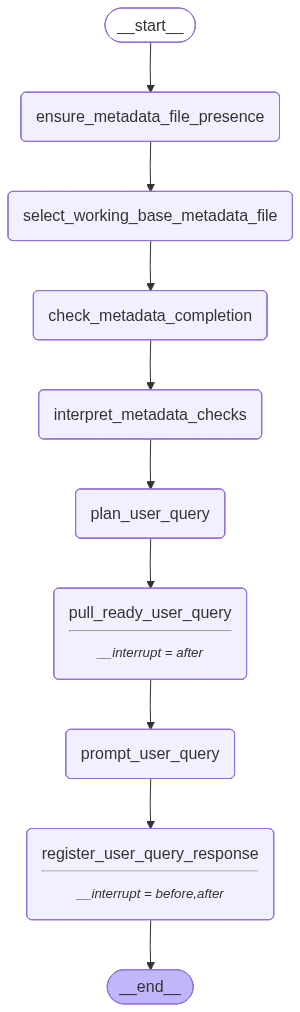

In [6]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
import random

thread = {"configurable": {"thread_id": str(random.randint(1, 100))}}

In [8]:
import pprint

In [9]:
def stream_until_iterruption(graph, *args):
    for event in graph.stream(*args, stream_mode="values"):
        print("\n==== new event ====")
        for k, v in event.items():
            print(f"---- {k} ----")
            pprint.pp(v, indent=4)

> **_Now we begin the interaction_**

In [10]:
# Run the graph until the first interruption
stream_until_iterruption(graph, {}, thread)


==== new event ====
---- messages ----
[]
---- base_metadata_files ----
['/home/jovyan/work/_demo/base_metadata.json']

==== new event ====
---- messages ----
[]
---- base_metadata_files ----
['/home/jovyan/work/_demo/base_metadata.json']
---- selected_base_metadata_file ----
'/home/jovyan/work/_demo/base_metadata.json'

==== new event ====
---- messages ----
[]
---- base_metadata_files ----
['/home/jovyan/work/_demo/base_metadata.json']
---- selected_base_metadata_file ----
'/home/jovyan/work/_demo/base_metadata.json'
---- schema_validation_errors ----
[   {   'message': "'entry_id' is a required property",
        'encountered_value': [   'entry_version',
                                 'entry_id',
                                 'description',
                                 'products'],
        'json_path': '$',
        'failed_key': 'required'},
    {   'message': "'description' is a required property",
        'encountered_value': [   'entry_version',
                        

> **_After the first interrupt -- first user query is ready_**

In [11]:
state = graph.get_state(thread)
pprint.pp(state.values.keys())
print("~~~~")
for key in state.values.keys():
    print(f"\n---- {key} ----")
    pprint.pp(state.values[key], indent=4)

dict_keys(['messages', 'base_metadata_files', 'selected_base_metadata_file', 'schema_validation_errors', 'errors_summary', 'query_plan', 'query_plan_completed', 'current_step_pointer', 'current_query_prompt', 'original_metadata'])
~~~~

---- messages ----
[   AIMessage(content="Based on the JSON schema validation errors provided, here are the issues that occurred:\n\n- The property `entry_id` is required but missing from the data. It should be included in the metadata file.\n\n- The property `description` is also required and must be specified in the metadata file.\n\nThe specific error messages indicate:\n1. `'entry_id' is a required property`\n2. `'description' is a required property`\n\nBoth of these errors are encountered at the root level (`$`) of the JSON schema validation, suggesting that they apply to the top-level properties expected by the schema.\n\nTo resolve these issues, ensure that the `entry_id` and `description` fields are properly defined in your MIAGIS base metadata 

In [12]:
pprint.pp(state.values["query_plan"], indent=4)
print("~~~~")
pprint.pp(state.values["query_plan_completed"], indent=4)
print("~~~~")
pprint.pp(state.values["current_step_pointer"], indent=4)
print("~~~~")
pprint.pp(state.values["current_query_prompt"], indent=4)

QueryPlan(queries=[QueryStep(id=1, key='entry_id', json_path='$.entry_id', priority=5, query='Please provide a unique identifier for this data entry.'), QueryStep(id=2, key='description', json_path='$.description', priority=5, query='Please describe the content and purpose of this GIS data set in detail.')])
~~~~
False
~~~~
0
~~~~
QueryStep(id=1, key='entry_id', json_path='$.entry_id', priority=5, query='Please provide a unique identifier for this data entry.')


> **_After the first interrupt - will continue with prompting the user_**
>
> - make sure to enter a value

In [13]:
from unittest.mock import patch # to bypass the user input

DEFAULT_ID="test-miagis-application-for-flood-risk-mapping"

# if the formed query aimed at the entry_id, let's patch it with a default
if "entry_id" in state.values["current_query_prompt"].json_path: 
    # return a default value if `input` is called.
    with patch('builtins.input', return_value=DEFAULT_ID):
        stream_until_iterruption(graph, None, thread)
else: 
    stream_until_iterruption(graph, None, thread)


==== new event ====
---- messages ----
[   AIMessage(content="Based on the JSON schema validation errors provided, here are the issues that occurred:\n\n- The property `entry_id` is required but missing from the data. It should be included in the metadata file.\n\n- The property `description` is also required and must be specified in the metadata file.\n\nThe specific error messages indicate:\n1. `'entry_id' is a required property`\n2. `'description' is a required property`\n\nBoth of these errors are encountered at the root level (`$`) of the JSON schema validation, suggesting that they apply to the top-level properties expected by the schema.\n\nTo resolve these issues, ensure that the `entry_id` and `description` fields are properly defined in your MIAGIS base metadata file. These two required properties must be included with their corresponding values for the data to pass the JSON schema validation successfully.", additional_kwargs={}, response_metadata={'model': 'granite4:3b', 'c

> **_After second interrupt - user response given but not registed_**

In [14]:
print(graph.get_state(thread).values["current_query_response"])
print(graph.get_state(thread).values["selected_base_metadata_file"])

test-miagis-application-for-flood-risk-mapping
/home/jovyan/work/_demo/base_metadata.json


> **_After the second interrupt -- metadata will now be updated_**

In [15]:
stream_until_iterruption(graph, None, thread)


==== new event ====
---- messages ----
[   AIMessage(content="Based on the JSON schema validation errors provided, here are the issues that occurred:\n\n- The property `entry_id` is required but missing from the data. It should be included in the metadata file.\n\n- The property `description` is also required and must be specified in the metadata file.\n\nThe specific error messages indicate:\n1. `'entry_id' is a required property`\n2. `'description' is a required property`\n\nBoth of these errors are encountered at the root level (`$`) of the JSON schema validation, suggesting that they apply to the top-level properties expected by the schema.\n\nTo resolve these issues, ensure that the `entry_id` and `description` fields are properly defined in your MIAGIS base metadata file. These two required properties must be included with their corresponding values for the data to pass the JSON schema validation successfully.", additional_kwargs={}, response_metadata={'model': 'granite4:3b', 'c

In [16]:
graph.get_state(thread).values

{'messages': [AIMessage(content="Based on the JSON schema validation errors provided, here are the issues that occurred:\n\n- The property `entry_id` is required but missing from the data. It should be included in the metadata file.\n\n- The property `description` is also required and must be specified in the metadata file.\n\nThe specific error messages indicate:\n1. `'entry_id' is a required property`\n2. `'description' is a required property`\n\nBoth of these errors are encountered at the root level (`$`) of the JSON schema validation, suggesting that they apply to the top-level properties expected by the schema.\n\nTo resolve these issues, ensure that the `entry_id` and `description` fields are properly defined in your MIAGIS base metadata file. These two required properties must be included with their corresponding values for the data to pass the JSON schema validation successfully.", additional_kwargs={}, response_metadata={'model': 'granite4:3b', 'created_at': '2026-01-14T12:05:

In [21]:
keys = ["original_metadata", "updated_metadata"]
for key in keys:
    print(f"\n---- {key} ----")
    pprint.pp(graph.get_state(thread).values[key], indent=4)


---- original_metadata ----
{   'entry_version': 1,
    'products': [   'Map 1 Potential hot-spot map for flood risk',
                    'Netherlands map',
                    'Risk_model_0_100']}

---- updated_metadata ----
MetadataUpdate(metadata={'entry_version': 1, 'products': ['Map 1 Potential hot-spot map for flood risk', 'Netherlands map', 'Risk_model_0_100'], 'entry_id': 'test-miagis-application-for-flood-risk-mapping'})


> **_Now we can check the result of the metadata update_**

In [18]:
import json
with open(graph.get_state(thread).values["selected_base_metadata_file"], "r") as bmf:
    base_metadata = json.load(bmf)
    print(base_metadata)

{'entry_version': 1, 'products': ['Map 1 Potential hot-spot map for flood risk', 'Netherlands map', 'Risk_model_0_100'], 'entry_id': 'test-miagis-application-for-flood-risk-mapping'}


In [19]:
assert base_metadata["entry_id"] == DEFAULT_ID